# M2 – Semaine 1 : mesurer la baseline

**Objectif :** mesurer le modèle existant (`andy279/convnext-tiny-ham10000-lesion-disjoint`) **sans le modifier**, sur la **validation**.
Ce sera le point de comparaison de tous tes essais.

**Règles :** on utilise uniquement `splits.csv` pour les ensembles, et l'ordre des classes officiel vient uniquement de `classes.json`.
Le **test** n'est utilisé qu'une seule fois, en semaine 4.

Exécute les cellules **une par une** (Maj+Entrée) et lis chaque sortie avant de continuer.

## 1. Préparation : chemins, appareil (GPU ou CPU)

In [2]:
import os, glob, json, time, unicodedata, re
import numpy as np, pandas as pd, torch, timm
import matplotlib.pyplot as plt
from PIL import Image
from huggingface_hub import hf_hub_download

DATA = os.path.expanduser("~/projet/data")   # splits.csv, classes.json, class_weights.csv
HAM  = f"{DATA}/ham"                          # images HAM10000
REPO = "andy279/convnext-tiny-ham10000-lesion-disjoint"
ESSAI = "baseline_convnext_tiny_andy279"

def choisir_appareil():
    if torch.cuda.is_available():
        try:
            (torch.zeros(8, device="cuda") + 1).sum().item()   # petit test réel du GPU
            return "cuda"
        except Exception as e:
            print("GPU visible mais inutilisable, on passe en CPU :", e)
    return "cpu"

device = choisir_appareil()
print("torch", torch.__version__, "| timm", timm.__version__, "| appareil :", device)
if device == "cuda":
    print("GPU :", torch.cuda.get_device_name(0))

/home/hadil/projet/M2_modele/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


torch 2.15.0+cpu | timm 1.0.31 | appareil : cpu


## 2. Regarder les données (toujours comprendre avant de coder)

In [3]:
splits = pd.read_csv(f"{DATA}/splits.csv")
classes_raw = json.load(open(f"{DATA}/classes.json"))

print("Forme :", splits.shape)
print("Colonnes :", splits.columns.tolist())
display(splits.head())
print("\nclasses.json :", classes_raw)
for c in splits.columns:
    if splits[c].nunique() <= 20:
        print(f"\n--- {c} ---")
        print(splits[c].value_counts())

Forme : (10015, 10)
Colonnes : ['image_id', 'lesion_id', 'dx', 'label', 'risque', 'split', 'age', 'sex', 'localization', 'dx_type']


,image_id,lesion_id,dx,label,risque,split,age,sex,localization,dx_type
0,ISIC_0024309,HAM_0000484,nv,5,bénin,test,40.0,male,trunk,follow_up
1,ISIC_0024312,HAM_0001359,bkl,2,bénin,test,75.0,male,lower extremity,histo
2,ISIC_0024323,HAM_0002493,mel,4,malin,test,50.0,male,lower extremity,histo
3,ISIC_0024335,HAM_0004431,nv,5,bénin,test,45.0,female,lower extremity,follow_up
4,ISIC_0024345,HAM_0006872,bcc,1,malin,test,85.0,male,back,histo



classes.json : {'codes': ['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc'], 'label_index': {'akiec': 0, 'bcc': 1, 'bkl': 2, 'df': 3, 'mel': 4, 'nv': 5, 'vasc': 6}, 'noms': {'akiec': 'Kératose actinique / carcinome intra-épithélial', 'bcc': 'Carcinome basocellulaire', 'bkl': 'Kératose bénigne', 'df': 'Dermatofibrome', 'mel': 'Mélanome', 'nv': 'Naevus mélanocytaire', 'vasc': 'Lésion vasculaire'}, 'risque': {'akiec': 'précancéreux', 'bcc': 'malin', 'bkl': 'bénin', 'df': 'bénin', 'mel': 'malin', 'nv': 'bénin', 'vasc': 'bénin'}, 'seed': 42, 'split': '70/15/15 par lesion_id, stratifié par dx'}

--- dx ---
dx
nv       6705
mel      1113
bkl      1099
bcc       514
akiec     327
vasc      142
df        115
Name: count, dtype: int64

--- label ---
label
5    6705
4    1113
2    1099
1     514
0     327
6     142
3     115
Name: count, dtype: int64

--- risque ---
risque
bénin           8061
malin           1627
précancéreux     327
Name: count, dtype: int64

--- split ---
split
train    7002


## 3. Repérer les colonnes et les classes
La cellule devine les noms de colonnes. **Lis ce qu'elle a deviné** ; si c'est faux, décommente les lignes « MANUEL » et corrige.

In [4]:
def norm(s):
    s = unicodedata.normalize("NFKD", str(s)).encode("ascii", "ignore").decode()
    return re.sub(r"[^a-z0-9]+", "_", s.lower()).strip("_")

def trouver(cands, cols):
    low = {norm(c): c for c in cols}
    for k in cands:
        if k in low:
            return low[k]
    return None

COL_ID    = trouver(["image_id", "image", "isic_id", "id", "filename", "file", "fichier"], splits.columns)
COL_SPLIT = trouver(["split", "ensemble", "set", "subset", "partition"], splits.columns)
COL_LABEL = trouver(["label_id", "numero_classe", "num_classe", "class_id", "label", "target", "y"], splits.columns)
COL_NAME  = trouver(["dx", "classe", "class", "class_name", "nom_classe", "diagnosis"], splits.columns)

# --- MANUEL (décommente et corrige si la détection est fausse) ---
# COL_ID, COL_SPLIT, COL_LABEL, COL_NAME = "image_id", "ensemble", "numero_classe", None

print("COL_ID    =", COL_ID)
print("COL_SPLIT =", COL_SPLIT)
print("COL_LABEL =", COL_LABEL)
print("COL_NAME  =", COL_NAME)
assert COL_ID and COL_SPLIT and (COL_LABEL or COL_NAME), "Colonnes non reconnues : renseigne-les dans la partie MANUEL."

# Noms de classes alternatifs -> code officiel
ALIAS = {
    "actinic keratoses": "akiec", "actinic keratosis": "akiec",
    "basal cell carcinoma": "bcc",
    "benign keratosis-like lesions": "bkl", "benign keratosis": "bkl",
    "dermatofibroma": "df",
    "melanoma": "mel",
    "melanocytic nevi": "nv", "melanocytic nevus": "nv", "nevus": "nv",
    "vascular lesions": "vasc",
}

def lire_classes(d):
    """Renvoie {nom_en_minuscules: indice}, quel que soit le format du JSON."""
    # Formats de tes fichiers : classes.json (label_index / codes), label_map.json (id2label)
    if isinstance(d, dict) and isinstance(d.get("id2label"), dict):
        d = d["id2label"]
    elif isinstance(d, dict) and isinstance(d.get("label_index"), dict):
        d = d["label_index"]
    elif isinstance(d, dict) and isinstance(d.get("codes"), list):
        d = d["codes"]

    if isinstance(d, list) and all(isinstance(x, str) for x in d):
        res = {x.lower().strip(): i for i, x in enumerate(d)}
    elif isinstance(d, dict) and all(isinstance(v, (int, np.integer)) or (isinstance(v, str) and v.isdigit()) for v in d.values()):
        res = {k.lower().strip(): int(v) for k, v in d.items()}
    elif isinstance(d, dict) and all(str(k).isdigit() for k in d) and all(isinstance(v, str) for v in d.values()):
        res = {v.lower().strip(): int(k) for k, v in d.items()}
    else:
        raise ValueError("Format de classes non reconnu, envoie-moi ce contenu : " + str(d)[:400])
    # underscores -> espaces, puis noms longs -> codes officiels (akiec, bcc, bkl, df, mel, nv, vasc)
    return {ALIAS.get(k.replace("_", " "), k): v for k, v in res.items()}

officiel = lire_classes(classes_raw)            # ordre OFFICIEL (classes.json)
noms_officiel = [n for n, i in sorted(officiel.items(), key=lambda x: x[1])]
print("\nOrdre officiel :", officiel)

# Étiquette numérique officielle de chaque image
if COL_LABEL and pd.api.types.is_numeric_dtype(splits[COL_LABEL]):
    splits["_y"] = splits[COL_LABEL].astype(int)
else:
    src = COL_NAME if COL_NAME else COL_LABEL
    splits["_y"] = splits[src].astype(str).str.lower().str.strip().map(lambda s: officiel.get(ALIAS.get(s, s)))
assert splits["_y"].notna().all(), "Certaines étiquettes n'ont pas pu être converties."
splits["_y"] = splits["_y"].astype(int)

# Valeur désignant la validation
valeurs = {str(v).lower().strip(): v for v in splits[COL_SPLIT].unique()}
VAL_VALUE = next((valeurs[k] for k in ["val", "valid", "validation"] if k in valeurs), None)
assert VAL_VALUE is not None, f"Valeur de validation introuvable parmi {list(valeurs)} : renseigne VAL_VALUE à la main."
print("Ensemble utilisé pour la baseline :", VAL_VALUE)

COL_ID    = image_id
COL_SPLIT = split
COL_LABEL = label
COL_NAME  = dx

Ordre officiel : {'akiec': 0, 'bcc': 1, 'bkl': 2, 'df': 3, 'mel': 4, 'nv': 5, 'vasc': 6}
Ensemble utilisé pour la baseline : val


## 4. Retrouver les images
Les images sont dans plusieurs dossiers (`part_1`, `part_2`, ...). On les indexe par leur nom.

In [5]:
splits["_id"] = splits[COL_ID].astype(str).str.replace(r"\.(jpg|jpeg|png)$", "", regex=True, case=False)

paths = {}
for pat in ("*.jpg", "*.jpeg", "*.png"):
    for p in glob.glob(f"{HAM}/**/{pat}", recursive=True):
        paths.setdefault(os.path.splitext(os.path.basename(p))[0], p)
print(len(paths), "images trouvées sur le disque")

ev = splits[splits[COL_SPLIT] == VAL_VALUE].reset_index(drop=True)
manquantes = ev.loc[~ev["_id"].isin(paths), "_id"]
print(len(ev), "images dans l'ensemble évalué ;", len(manquantes), "introuvables")
assert len(manquantes) == 0, f"Images introuvables, par ex. : {manquantes.head().tolist()}"

print("\nRépartition des classes (ensemble évalué) :")
print(ev["_y"].map(dict(enumerate(noms_officiel))).value_counts())

10015 images trouvées sur le disque
1532 images dans l'ensemble évalué ; 0 introuvables

Répartition des classes (ensemble évalué) :
_y
nv       1034
mel       170
bkl       157
bcc        77
akiec      51
vasc       24
df         19
Name: count, dtype: int64


## 5. Charger le modèle existant
Si une erreur 401/403 apparaît : accepte les conditions sur la page du modèle Hugging Face, puis lance `hf auth login` dans le terminal.

In [6]:
from timm.data import resolve_data_config

try:
    cfg    = json.load(open(hf_hub_download(REPO, "run_config.json")))
    labels = json.load(open(hf_hub_download(REPO, "label_map.json")))
    id2label = {int(k): v for k, v in labels["id2label"].items()}

    model = timm.create_model(cfg["model_name"], pretrained=False, num_classes=len(id2label))
    sd = torch.load(hf_hub_download(REPO, "backbone.pt"), map_location="cpu")
    if isinstance(sd, dict) and "state_dict" in sd:
        sd = sd["state_dict"]
    model.load_state_dict(sd)
    model.eval()
except Exception as e:
    raise RuntimeError("Chargement du modèle impossible. Vérifie : conditions acceptées sur Hugging Face, "
                       "`hf auth login` fait, connexion Internet.\nDétail : " + repr(e))

data_cfg = resolve_data_config({}, model=model)
tf = timm.data.create_transform(**data_cfg, is_training=False)   # prétraitement du modèle lui-même
model = model.to(device)

print("run_config.json :", cfg)
print("label_map.json  :", labels)
print("Prétraitement utilisé :", data_cfg)
print("Sorties du modèle :", model.num_classes)

run_config.json : {'model_name': 'convnext_tiny.fb_in22k_ft_in1k', 'input_size': [3, 224, 224], 'mean': [0.485, 0.456, 0.406], 'std': [0.229, 0.224, 0.225], 'interpolation': 'bicubic', 'crop_pct': 0.875}
label_map.json  : {'id2label': {'0': 'actinic_keratoses', '1': 'basal_cell_carcinoma', '2': 'benign_keratosis-like_lesions', '3': 'dermatofibroma', '4': 'melanocytic_Nevi', '5': 'melanoma', '6': 'vascular_lesions'}, 'label2id': {'actinic_keratoses': 0, 'basal_cell_carcinoma': 1, 'benign_keratosis-like_lesions': 2, 'dermatofibroma': 3, 'melanocytic_Nevi': 4, 'melanoma': 5, 'vascular_lesions': 6}}
Prétraitement utilisé : {'input_size': (3, 224, 224), 'interpolation': 'bicubic', 'mean': (0.485, 0.456, 0.406), 'std': (0.229, 0.224, 0.225), 'crop_pct': 0.875, 'crop_mode': 'center'}
Sorties du modèle : 7


## 6. Correspondance des classes (point le plus important)
Le modèle et `classes.json` n'ont pas forcément le même ordre. Sans cette étape, tu mesurerais une erreur d'ordre, pas la qualité du modèle.

In [7]:
modele = lire_classes(labels)                  # {nom: indice dans le MODÈLE}
print("Ordre du modèle  :", dict(sorted(modele.items(), key=lambda x: x[1])))
print("Ordre officiel   :", dict(sorted(officiel.items(), key=lambda x: x[1])))

inconnues = [n for n in modele if n not in officiel]
assert not inconnues, f"Noms du modèle absents de classes.json : {inconnues} -> complète ALIAS plus haut."
assert model.num_classes == len(officiel) == len(modele), "Nombre de classes différent !"

# perm[i] = indice officiel de la classe numéro i du modèle
perm = [None] * len(modele)
for nom, i_mod in modele.items():
    perm[i_mod] = officiel[nom]
assert sorted(perm) == list(range(len(officiel)))
print("\nperm (indice modèle -> indice officiel) :", perm)
for i, p in enumerate(perm):
    print(f"  modèle {i} ({[n for n,v in modele.items() if v==i][0]})  ->  officiel {p} ({noms_officiel[p]})")

Ordre du modèle  : {'akiec': 0, 'bcc': 1, 'bkl': 2, 'df': 3, 'nv': 4, 'mel': 5, 'vasc': 6}
Ordre officiel   : {'akiec': 0, 'bcc': 1, 'bkl': 2, 'df': 3, 'mel': 4, 'nv': 5, 'vasc': 6}

perm (indice modèle -> indice officiel) : [0, 1, 2, 3, 5, 4, 6]
  modèle 0 (akiec)  ->  officiel 0 (akiec)
  modèle 1 (bcc)  ->  officiel 1 (bcc)
  modèle 2 (bkl)  ->  officiel 2 (bkl)
  modèle 3 (df)  ->  officiel 3 (df)
  modèle 4 (nv)  ->  officiel 5 (nv)
  modèle 5 (mel)  ->  officiel 4 (mel)
  modèle 6 (vasc)  ->  officiel 6 (vasc)


## 7. Prédictions
`model.eval()` + `torch.inference_mode()` : on ne calcule pas de gradients, on ne fait que prédire.

In [8]:
class DS(torch.utils.data.Dataset):
    def __init__(self, df): self.df = df
    def __len__(self): return len(self.df)
    def __getitem__(self, i):
        r = self.df.iloc[i]
        img = Image.open(paths[r["_id"]]).convert("RGB")
        return tf(img), int(r["_y"])

dl = torch.utils.data.DataLoader(DS(ev), batch_size=32, shuffle=False, num_workers=0)

P, Y = [], []
t0 = time.time()
model.eval()
with torch.inference_mode():
    for b, (x, y) in enumerate(dl):
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=(device == "cuda")):
            logits = model(x.to(device))
        P.append(torch.softmax(logits.float(), 1).cpu().numpy())
        Y.append(y.numpy())
        if b % 5 == 0:
            print(f"  lot {b+1}/{len(dl)}  ({time.time()-t0:.0f} s)", flush=True)
P, Y = np.concatenate(P), np.concatenate(Y)

# On remet les colonnes dans l'ORDRE OFFICIEL
P_off = np.zeros_like(P)
P_off[:, perm] = P
pred = P_off.argmax(1)
np.save("probs_baseline_val.npy", P_off)
np.save("y_val.npy", Y)
print(f"Terminé en {time.time()-t0:.0f} s pour {len(Y)} images")

  lot 1/48  (5 s)
  lot 6/48  (17 s)
  lot 11/48  (29 s)
  lot 16/48  (40 s)
  lot 21/48  (52 s)
  lot 26/48  (64 s)
  lot 31/48  (75 s)
  lot 36/48  (87 s)
  lot 41/48  (99 s)
  lot 46/48  (111 s)
Terminé en 115 s pour 1532 images


In [9]:
#exécute la cellule sur split_manifest.json donnée plus haut, envoie-moi sa sortie, et j’écris la cellule qui compte combien de tes images de validation et de test ont servi à entraîner le modèle.

#Cellule A : regarder split_manifest.json

import re
man = json.load(open(hf_hub_download(REPO, "split_manifest.json")))
print("Type :", type(man).__name__)
if isinstance(man, dict):
    for k, v in man.items():
        if isinstance(v, dict):
            print(k, "-> dict, clés :", list(v.keys())[:6])
        elif isinstance(v, list):
            print(k, "-> liste de", len(v), "éléments, ex. :", v[:3])
        else:
            print(k, "->", str(v)[:100])

Type : dict
lesion_disjoint -> True
seed -> 42
train_lesion_ids -> liste de 5228 éléments, ex. : ['HAM_0000001', 'HAM_0000002', 'HAM_0000003']
val_lesion_ids -> liste de 1121 éléments, ex. : ['HAM_0000000', 'HAM_0000006', 'HAM_0000008']
test_lesion_ids -> liste de 1121 éléments, ex. : ['HAM_0000007', 'HAM_0000024', 'HAM_0000025']
train_image_ids -> liste de 9305 éléments, ex. : ['ISIC_0024329', 'ISIC_0024450', 'ISIC_0024511']
val_image_ids -> liste de 2041 éléments, ex. : ['ISIC_0024418', 'ISIC_0024463', 'ISIC_0024468']
test_image_ids -> liste de 2008 éléments, ex. : ['ISIC_0024372', 'ISIC_0024646', 'ISIC_0024843']


In [10]:
#Cellule B : compter la fuite :- Images : % de tes images de validation (ou de test) que le modèle a déjà vues pendant son entraînement,- Lésion : % d’images dont la lésion est dans son train, même si la photo exacte est différente

imgs_train = set(man["train_image_ids"])
les_train  = set(man["train_lesion_ids"])
print(f"Train du modèle : {len(imgs_train)} images uniques, {len(les_train)} lésions")

print("\n=== Combien de NOS images / lésions le modèle a-t-il vues à l'entraînement ? ===")
for ens in splits[COL_SPLIT].unique():
    sub = splits[splits[COL_SPLIT] == ens]
    n = len(sub)
    n_img = sub["_id"].isin(imgs_train).sum()
    n_les = sub["lesion_id"].isin(les_train).sum()
    print(f"{str(ens):6s}: images vues {n_img}/{n} ({100*n_img/n:.1f} %) ; lésions vues {n_les}/{n} ({100*n_les/n:.1f} %)")

Train du modèle : 6973 images uniques, 5228 lésions

=== Combien de NOS images / lésions le modèle a-t-il vues à l'entraînement ? ===
test  : images vues 1035/1481 (69.9 %) ; lésions vues 1035/1481 (69.9 %)
train : images vues 4877/7002 (69.7 %) ; lésions vues 4877/7002 (69.7 %)
val   : images vues 1061/1532 (69.3 %) ; lésions vues 1061/1532 (69.3 %)


In [11]:
#Cellule C (bonus) : la baseline « propre » : Elle recalcule les métriques sur les seules images de validation dont la lésion n’est pas dans le train du modèle, donc une estimation plus honnête.

from sklearn.metrics import balanced_accuracy_score, f1_score, accuracy_score

propre = ~ev["lesion_id"].isin(les_train).values
print(f"Images de validation « propres » : {propre.sum()} / {len(ev)}")

if propre.sum() >= 50:
    Yp, Pp = Y[propre], pred[propre]
    i_mel = officiel["mel"]
    n_mel = (Yp == i_mel).sum()
    rec_mel = ((Pp == i_mel) & (Yp == i_mel)).sum() / max(n_mel, 1)
    print(f"accuracy      : {accuracy_score(Yp, Pp):.3f}")
    print(f"balanced acc  : {balanced_accuracy_score(Yp, Pp):.3f}")
    print(f"F1 macro      : {f1_score(Yp, Pp, average='macro'):.3f}")
    print(f"recall mel    : {rec_mel:.3f}  (sur {n_mel} mélanomes)")
else:
    print("Trop peu d'images propres pour calculer des métriques fiables.")

Images de validation « propres » : 471 / 1532
accuracy      : 0.798
balanced acc  : 0.866
F1 macro      : 0.786
recall mel    : 0.692  (sur 52 mélanomes)


In [ ]:
#Cellule D : enregistrer les métriques propres (seules les images dont la lésion n'est pas dans le train du modele) dans ablation.csv et config.json

i_mel = officiel["mel"]
Yp, Pp = Y[propre], pred[propre]
n_mel = int((Yp == i_mel).sum())

res_propre = {
    "essai": "baseline_convnext_tiny_andy279_propre",
    "description": f"meme modele, evalue sur les {int(propre.sum())} images de val dont la lesion n'est pas dans le train du modele",
    "accuracy": round(accuracy_score(Yp, Pp), 4),
    "balanced_acc": round(balanced_accuracy_score(Yp, Pp), 4),
    "f1_macro": round(f1_score(Yp, Pp, average="macro"), 4),
    "recall_mel": round(float(((Pp == i_mel) & (Yp == i_mel)).sum() / max(n_mel, 1)), 4),
}

old = pd.read_csv("ablation.csv")
old = old[old["essai"] != res_propre["essai"]]
pd.concat([old, pd.DataFrame([res_propre])], ignore_index=True).to_csv("ablation.csv", index=False)

conf = json.load(open("config.json"))
conf["metriques_validation_propre"] = res_propre
conf["avertissement"] = ("Les metriques_validation sont gonflees : environ 69 % des images de validation ont leur "
                         "lesion dans le train du modele. Utiliser metriques_validation_propre.")
json.dump(conf, open("config.json", "w"), indent=2, ensure_ascii=False)
display(pd.read_csv("ablation.csv"))

,essai,description,accuracy,balanced_acc,f1_macro,recall_mel
0,baseline_convnext_tiny_andy279,modele existant andy279/convnext-tiny-ham10000...,0.8838,0.9338,0.8844,0.8588
1,baseline_convnext_tiny_andy279_propre,"meme modele, evalue sur les 471 images de val ...",0.7983,0.8661,0.7856,0.6923


## 8. Métriques
- **Accuracy** : % de bonnes réponses (trompeuse : la classe `nv` domine).
- **Balanced accuracy / F1 macro** : traitent toutes les classes à égalité (métrique principale).
- **Recall de `mel`** : sur 100 vrais mélanomes, combien sont détectés (objectif ≥ 85 %).

{'essai': 'baseline_convnext_tiny_andy279', 'description': 'modele existant andy279/convnext-tiny-ham10000-lesion-disjoint non modifie, evalue sur val', 'accuracy': 0.8838, 'balanced_acc': 0.9338, 'f1_macro': 0.8844, 'recall_mel': 0.8588}

              precision    recall  f1-score   support

       akiec      0.725     0.980     0.833        51
         bcc      0.871     0.961     0.914        77
         bkl      0.754     0.860     0.804       157
          df      1.000     1.000     1.000        19
         mel      0.646     0.859     0.737       170
          nv      0.975     0.876     0.923      1034
        vasc      0.960     1.000     0.980        24

    accuracy                          0.884      1532
   macro avg      0.847     0.934     0.884      1532
weighted avg      0.903     0.884     0.889      1532



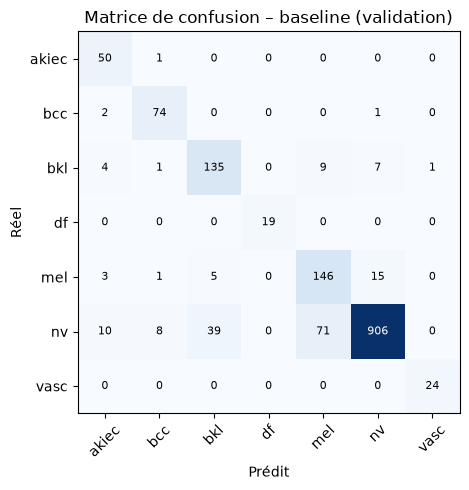

In [12]:
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, classification_report, confusion_matrix

labels_idx = list(range(len(noms_officiel)))
cm = confusion_matrix(Y, pred, labels=labels_idx)
i_mel = officiel["mel"]
recall_mel = cm[i_mel, i_mel] / max(cm[i_mel].sum(), 1)

res = {
    "essai": ESSAI,
    "description": f"modele existant {REPO} non modifie, evalue sur {VAL_VALUE}",
    "accuracy": round(accuracy_score(Y, pred), 4),
    "balanced_acc": round(balanced_accuracy_score(Y, pred), 4),
    "f1_macro": round(f1_score(Y, pred, average="macro"), 4),
    "recall_mel": round(float(recall_mel), 4),
}
print(res)
print()
print(classification_report(Y, pred, labels=labels_idx, target_names=noms_officiel, digits=3, zero_division=0))

fig, ax = plt.subplots(figsize=(6, 5))
ax.imshow(cm, cmap="Blues")
ax.set_xticks(labels_idx, noms_officiel, rotation=45); ax.set_yticks(labels_idx, noms_officiel)
ax.set_xlabel("Prédit"); ax.set_ylabel("Réel"); ax.set_title("Matrice de confusion – baseline (validation)")
for i in labels_idx:
    for j in labels_idx:
        ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max()/2 else "black", fontsize=8)
plt.tight_layout(); plt.savefig("confusion_baseline_val.png", dpi=150); plt.show()

**À vérifier :** la diagonale de la matrice doit dominer. Si le modèle semble « décalé » (ex. tout prédit comme une autre classe), l'ordre des classes est faux : relis la cellule 6.

## 9. Première ligne du tableau d'ablation

In [13]:
ABL = "ablation.csv"
new = pd.DataFrame([res])
if os.path.exists(ABL):
    old = pd.read_csv(ABL)
    old = old[old["essai"] != res["essai"]]
    new = pd.concat([old, new], ignore_index=True)
new.to_csv(ABL, index=False)
display(new)

,essai,description,accuracy,balanced_acc,f1_macro,recall_mel
0,baseline_convnext_tiny_andy279,modele existant andy279/convnext-tiny-ham10000...,0.8838,0.9338,0.8844,0.8588


## 10. Vitesse, taille et export (pour M3)
Cibles du projet : modèle ≤ 250 Mo et inférence ≤ 3 s sur CPU.

In [14]:
model = model.cpu().eval()
torch.save(model.state_dict(), "baseline.pth")
taille_mo = os.path.getsize("baseline.pth") / 1e6

x = tf(Image.open(paths[ev["_id"][0]]).convert("RGB")).unsqueeze(0)
with torch.inference_mode():
    for _ in range(2): model(x)                       # échauffement
    t0 = time.time()
    for _ in range(10): model(x)
    t_cpu = (time.time() - t0) / 10

print(f"Taille du fichier : {taille_mo:.1f} Mo (limite 250)")
print(f"Inférence CPU     : {t_cpu:.2f} s par image (limite 3 s)")

conf = {
    "model_repo": REPO,
    "architecture": (getattr(model, "pretrained_cfg", {}) or {}).get("architecture"),
    "classes_ordre_modele": [n for n, i in sorted(modele.items(), key=lambda x: x[1])],
    "classes_ordre_officiel": noms_officiel,
    "perm_modele_vers_officiel": perm,
    "input_size": list(data_cfg["input_size"]),
    "mean": list(data_cfg["mean"]), "std": list(data_cfg["std"]),
    "interpolation": data_cfg.get("interpolation"), "crop_pct": data_cfg.get("crop_pct"),
    "metriques_validation": res,
}
json.dump(conf, open("config.json", "w"), indent=2, ensure_ascii=False)
print("Fichiers écrits : baseline.pth, config.json, ablation.csv, probs_baseline_val.npy")

Taille du fichier : 111.4 Mo (limite 250)
Inférence CPU     : 0.07 s par image (limite 3 s)
Fichiers écrits : baseline.pth, config.json, ablation.csv, probs_baseline_val.npy


## Limites à noter dans le rapport
- Ce modèle n'a **pas** été entraîné avec notre `splits.csv` : certaines images de notre validation/test ont pu servir à son entraînement → scores possiblement flatteurs.
- Il utilisait déjà une perte pondérée par classe : l'effet de la Weighted CrossEntropy sera donc moins visible dans notre ablation.
- La comparaison honnête sera la **seconde baseline** entraînée depuis ImageNet avec notre `splits.csv` (semaine 2).
- Données dermatoscopiques uniquement ; outil pédagogique, pas un outil de diagnostic.

**Prochaine étape :** `train.py` (semaine 2).